# 🧪 Entrenamiento v5 — DenseNet201 + HAM10000
## Mejoras respecto a v4:
1. ✅ Fix `.repeat()` en train_ds (bug crítico de v4: solo 300/437 steps por época)
2. ✅ Augmentation agresiva para clases raras (`df`, `vasc`, `akiec`)
3. ✅ Fase 1: 40 épocas (↑ de 30)
4. ✅ Fine-tuning gradual: Fase 2a (25 capas) → Fase 2b (100 capas)
5. ✅ LR warmup al inicio de cada fase de fine-tuning

**Proyecto APPR · Michelle Ruiz**

## 2. Verificar GPU disponible

In [1]:
import subprocess
result = subprocess.run(['nvidia-smi'], capture_output=True, text=True)
print(result.stdout)

Sun Nov 15 21:34:36 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 3. Importaciones

In [2]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

print(f"TensorFlow: {tf.__version__}")
print(f"GPU disponible: {tf.config.list_physical_devices('GPU')}")

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 4. Configuración

In [22]:
# ─── Semilla global ───────────────────────────────────────────
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ─── Rutas en Kaggle ─────────────────────────────────────────
NUMPY_DIR    = '/kaggle/input/datasets/michellercarranza/ham10000-numpy'

TRAIN_X_PATH = os.path.join(NUMPY_DIR, 'train_X.npy')
TRAIN_Y_PATH = os.path.join(NUMPY_DIR, 'train_y.npy')
VAL_X_PATH   = os.path.join(NUMPY_DIR, 'validation_X.npy')
VAL_Y_PATH   = os.path.join(NUMPY_DIR, 'validation_y.npy')
TEST_X_PATH  = os.path.join(NUMPY_DIR, 'test_X.npy')
TEST_Y_PATH  = os.path.join(NUMPY_DIR, 'test_y.npy')

MODELS_DIR   = '/kaggle/working/modelos_v5'
os.makedirs(MODELS_DIR, exist_ok=True)

MODEL_PHASE1  = os.path.join(MODELS_DIR, 'densenet201_v5_phase1_best.keras')
MODEL_PHASE2A = os.path.join(MODELS_DIR, 'densenet201_v5_phase2a_best.keras')
MODEL_PHASE2B = os.path.join(MODELS_DIR, 'densenet201_v5_phase2b_best.keras')

# ─── Hiperparámetros ─────────────────────────────────────────
IMG_SIZE   = 224
BATCH_SIZE = 32

EPOCHS_PHASE1  = 40
EPOCHS_PHASE2A = 25
EPOCHS_PHASE2B = 25

LR_PHASE1  = 1e-3
LR_PHASE2A = 2e-5
LR_PHASE2B = 5e-6

UNFREEZE_PHASE2A = 25
UNFREEZE_PHASE2B = 100

# ─── Clases ──────────────────────────────────────────────────
CLASS_NAMES  = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
NUM_CLASSES  = len(CLASS_NAMES)
RARE_INDICES = {0: 'akiec', 3: 'df', 4: 'vasc'}

print("✅ Configuración cargada")
print(f"   Épocas Fase 1:   {EPOCHS_PHASE1}")
print(f"   Épocas Fase 2a:  {EPOCHS_PHASE2A} ({UNFREEZE_PHASE2A} capas)")
print(f"   Épocas Fase 2b:  {EPOCHS_PHASE2B} ({UNFREEZE_PHASE2B} capas)")
print(f"   LR Fase 1:       {LR_PHASE1}")
print(f"   LR Fase 2a:      {LR_PHASE2A}")
print(f"   LR Fase 2b:      {LR_PHASE2B}")
print(f"   NUMPY_DIR:       {NUMPY_DIR}")
print(f"   MODELS_DIR:      {MODELS_DIR}")

✅ Configuración cargada
   Épocas Fase 1:   40
   Épocas Fase 2a:  25 (25 capas)
   Épocas Fase 2b:  25 (100 capas)
   LR Fase 1:       0.001
   LR Fase 2a:      2e-05
   LR Fase 2b:      5e-06
   NUMPY_DIR:       /kaggle/input/datasets/michellercarranza/ham10000-numpy
   MODELS_DIR:      /kaggle/working/modelos_v5


## 5. Cargar datos desde numpy

In [23]:
# ─── Cargar etiquetas (pequeñas, caben en RAM) ───────────────
print("Cargando etiquetas...")
y_train_raw = np.load(TRAIN_Y_PATH)
y_val_raw   = np.load(VAL_Y_PATH)
y_test_raw  = np.load(TEST_Y_PATH)

print(f"  train labels: {y_train_raw.shape}  — {len(y_train_raw)} imágenes")
print(f"  val labels:   {y_val_raw.shape}")
print(f"  test labels:  {y_test_raw.shape}")

# ─── Val y Test: cargar completos en RAM (caben ~120 MB cada uno) ─
print("\nCargando val y test en RAM...")
X_val_arr  = np.load(VAL_X_PATH).astype(np.float32)
X_test_arr = np.load(TEST_X_PATH).astype(np.float32)
print(f"  val:  {X_val_arr.shape}  ({X_val_arr.nbytes/1e6:.0f} MB)")
print(f"  test: {X_test_arr.shape}  ({X_test_arr.nbytes/1e6:.0f} MB)")

# ─── Distribución original ───────────────────────────────────
dist = Counter(y_train_raw)
print("\nDistribución original del train set:")
for cls_idx, name in enumerate(CLASS_NAMES):
    n = dist[cls_idx]
    print(f"  [{cls_idx}] {name:6s}: {n:5d}  ({100*n/len(y_train_raw):.1f}%)")

Cargando etiquetas...
  train labels: (9577,)  — 9577 imágenes
  val labels:   (2492,)
  test labels:  (1285,)

Cargando val y test en RAM...
  val:  (2492, 224, 224, 3)  (1500 MB)
  test: (1285, 224, 224, 3)  (774 MB)

Distribución original del train set:
  [0] akiec :   315  (3.3%)
  [1] bcc   :   487  (5.1%)
  [2] bkl   :  1048  (10.9%)
  [3] df    :   110  (1.1%)
  [4] mel   :  1076  (11.2%)
  [5] nv    :  6405  (66.9%)
  [6] vasc  :   136  (1.4%)


## 6. Balanceo 2000/clase y class weights

In [24]:
# ─── Balanceo a 2000 imágenes por clase (con reemplazo) ──────
TARGET = 2000
rng = np.random.default_rng(SEED)

balanced_idx = []
for cls_idx in range(NUM_CLASSES):
    cls_indices = np.where(y_train_raw == cls_idx)[0]
    sampled = rng.choice(cls_indices, size=TARGET, replace=len(cls_indices) < TARGET)
    balanced_idx.append(sampled)
balanced_idx = np.concatenate(balanced_idx)
rng.shuffle(balanced_idx)

y_train_bal = y_train_raw[balanced_idx]  # shape (14000,)

print(f"Dataset balanceado: {len(balanced_idx)} imágenes ({TARGET}/clase × {NUM_CLASSES} clases)")

# ─── Class weights basados en distribución ORIGINAL ──────────
# (no en la balanceada — el paper EnsembleSkinNet usa distribución original)
total = len(y_train_raw)
class_weights = {}
for cls_idx in range(NUM_CLASSES):
    n_cls = dist[cls_idx]
    # formula: total / (num_classes * n_cls)
    class_weights[cls_idx] = total / (NUM_CLASSES * n_cls)

print("\nClass weights (basados en distribución original):")
for cls_idx, name in enumerate(CLASS_NAMES):
    print(f"  [{cls_idx}] {name:6s}: {class_weights[cls_idx]:.4f}")

Dataset balanceado: 14000 imágenes (2000/clase × 7 clases)

Class weights (basados en distribución original):
  [0] akiec : 4.3433
  [1] bcc   : 2.8093
  [2] bkl   : 1.3055
  [3] df    : 12.4377
  [4] mel   : 1.2715
  [5] nv    : 0.2136
  [6] vasc  : 10.0599


## 7. Data augmentation
### MEJORA 2: augmentation diferenciada por clase
- **Clases normales** (`mel`, `bkl`, `bcc`, `nv`): augmentation estándar
- **Clases raras** (`df`, `vasc`, `akiec`): augmentation agresiva con más variación

In [25]:
# ─── Augmentation estándar (clases normales) ─────────────────
augmentation_standard = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomBrightness(0.1),
], name='aug_standard')

# ─── Augmentation agresiva (clases raras) ─────────────────────
# Genera más variación porque hay muy pocas imágenes reales:
# df=110, vasc=142, akiec=327 → con 2000 targets, hay mucha repetición
augmentation_heavy = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),  # ↑ más orientaciones
    tf.keras.layers.RandomRotation(0.3),                    # ↑ más rotación
    tf.keras.layers.RandomZoom(0.2),                        # ↑ más zoom
    tf.keras.layers.RandomContrast(0.3),                    # ↑ variación de contraste
    tf.keras.layers.RandomBrightness(0.2),                  # ↑ variación de brillo
    tf.keras.layers.RandomTranslation(0.1, 0.1),            # ↑ desplazamiento
], name='aug_heavy')

# Índices de clases raras
RARE_INDICES = {0: 'akiec', 3: 'df', 4: 'vasc'}

@tf.function
def apply_augmentation(image, label):
    """Aplica augmentation diferenciada según si es clase rara o normal."""
    label_int = tf.argmax(label)
    is_rare = tf.reduce_any(tf.equal(label_int,
                             tf.constant(list(RARE_INDICES.keys()), dtype=tf.int64)))
    # tf.cond aplica la rama correcta según la clase
    image = tf.cond(
        is_rare,
        lambda: augmentation_heavy(tf.expand_dims(image, 0), training=True)[0],
        lambda: augmentation_standard(tf.expand_dims(image, 0), training=True)[0]
    )
    return image, label

print("✅ Augmentation configurada:")
print("   Estándar (mel, bkl, bcc, nv): flip-H, rotation±10%, zoom±10%, brightness±10%")
print("   Agresiva (akiec, df, vasc):   flip-HV, rotation±30%, zoom±20%,")
print("                                  contrast±30%, brightness±20%, translation±10%")

✅ Augmentation configurada:
   Estándar (mel, bkl, bcc, nv): flip-H, rotation±10%, zoom±10%, brightness±10%
   Agresiva (akiec, df, vasc):   flip-HV, rotation±30%, zoom±20%,
                                  contrast±30%, brightness±20%, translation±10%


## 8. Pipeline tf.data

In [32]:
def make_train_dataset(X_path, indices, y_labels, batch_size=BATCH_SIZE):
    X_mmap = np.load(X_path, mmap_mode='r')
    y_one_hot = tf.keras.utils.to_categorical(y_labels, NUM_CLASSES).astype(np.float32)

    def gen():
        for i, lbl in zip(indices, y_one_hot):
            yield X_mmap[i].astype(np.float32), lbl

    ds = tf.data.Dataset.from_generator(
        gen,
        output_signature=(
            tf.TensorSpec(shape=(IMG_SIZE, IMG_SIZE, 3), dtype=tf.float32),
            tf.TensorSpec(shape=(NUM_CLASSES,),          dtype=tf.float32),
        )
    )

    ds = ds.shuffle(buffer_size=2000, seed=SEED)
    ds = ds.batch(batch_size)

    def augment_batch(images, labels):
        label_ints = tf.argmax(labels, axis=1)
        rare = tf.constant(list(RARE_INDICES.keys()), dtype=tf.int64)

        def aug_single(args):
            img, lbl_int = args
            is_rare = tf.reduce_any(tf.equal(lbl_int, rare))
            img = tf.cond(
                is_rare,
                lambda: augmentation_heavy(tf.expand_dims(img, 0), training=True)[0],
                lambda: augmentation_standard(tf.expand_dims(img, 0), training=True)[0],
            )
            return img

        images = tf.map_fn(
            aug_single,
            (images, label_ints),
            fn_output_signature=tf.float32
        )
        return images, labels

    ds = ds.map(augment_batch, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.repeat()
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


def make_eval_dataset(X_arr, y_labels, batch_size=BATCH_SIZE):
    y_one_hot = tf.keras.utils.to_categorical(y_labels, NUM_CLASSES).astype(np.float32)
    ds = tf.data.Dataset.from_tensor_slices((X_arr, y_one_hot))
    ds = ds.batch(batch_size).cache().prefetch(tf.data.AUTOTUNE)
    return ds


n_train = len(balanced_idx)
steps_per_epoch_train = n_train // BATCH_SIZE

train_ds = make_train_dataset(TRAIN_X_PATH, balanced_idx, y_train_bal)
val_ds   = make_eval_dataset(X_val_arr, y_val_raw)
test_ds  = make_eval_dataset(X_test_arr, y_test_raw)

print(f"✅ Datasets creados")
print(f"   Train: {n_train} imágenes → {steps_per_epoch_train} steps/época")
print(f"   Val:   {len(y_val_raw)} imágenes")
print(f"   Test:  {len(y_test_raw)} imágenes")

✅ Datasets creados
   Train: 14000 imágenes → 437 steps/época
   Val:   2492 imágenes
   Test:  1285 imágenes


## 9. Construcción del modelo DenseNet201

In [33]:
def build_model():
    """
    DenseNet201 + cabeza clasificadora Dense(512)→Dropout→Dense(7).
    Arquitectura idéntica a v4 (que sigue el paper EnsembleSkinNet).
    """
    base = tf.keras.applications.DenseNet201(
        include_top=False,
        weights='imagenet',
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = base(inputs, training=False)   # training=False → BatchNorm en modo inferencia
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(512, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)

    model = tf.keras.Model(inputs, outputs)
    return model, base


model, base_model = build_model()
total_params = model.count_params()
print(f"✅ Modelo construido")
print(f"   Parámetros totales:     {total_params:,}")
print(f"   Capas DenseNet201:      {len(base_model.layers)}")
print(f"   Input shape:            {model.input_shape}")

✅ Modelo construido
   Parámetros totales:     19,309,127
   Capas DenseNet201:      707
   Input shape:            (None, 224, 224, 3)


## 10. Focal Loss
Usada en Fase 2 (fine-tuning). En Fase 1 usamos CrossEntropy + class_weights,
porque al inicio del entrenamiento (pesos aleatorios) Focal Loss bloquea la convergencia.

In [42]:
class FocalLoss(tf.keras.losses.Loss):
    """
    Focal Loss: FL(p_t) = -alpha_t * (1-p_t)^gamma * log(p_t)
    gamma=2.0 según el paper EnsembleSkinNet.
    """
    def __init__(self, gamma=2.0, name='focal_loss'):
        super().__init__(name=name)
        self.gamma = gamma

    def call(self, y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0)
        ce = -y_true * tf.math.log(y_pred)          # cross-entropy por clase
        p_t = tf.reduce_sum(y_true * y_pred, axis=-1, keepdims=True)
        focal_weight = tf.pow(1.0 - p_t, self.gamma) # factor (1-p_t)^gamma
        loss = focal_weight * ce
        return tf.reduce_mean(tf.reduce_sum(loss, axis=-1))

focal_loss = FocalLoss(gamma=2.0)
print("✅ Focal Loss definida (gamma=2.0)")

✅ Focal Loss definida (gamma=2.0)


## 11. LR Warmup callback
### MEJORA 5: LR warmup al inicio de cada fase de fine-tuning
Durante las primeras 5 épocas, el LR sube linealmente de LR/5 hasta LR.
Protege los pesos de Fase 1 cuando se descongelan nuevas capas.

In [93]:
# Redefinir LRWarmupCallback con API correcta
class LRWarmupCallback(tf.keras.callbacks.Callback):
    def __init__(self, base_lr, warmup_epochs=5):
        super().__init__()
        self.base_lr = base_lr
        self.warmup_epochs = warmup_epochs

    def on_epoch_begin(self, epoch, logs=None):
        if epoch < self.warmup_epochs:
            new_lr = self.base_lr * (epoch + 1) / self.warmup_epochs
            self.model.optimizer.learning_rate.assign(new_lr)
            print(f"  [Warmup] Época {epoch+1}/{self.warmup_epochs} → LR = {new_lr:.2e}")
        elif epoch == self.warmup_epochs:
            self.model.optimizer.learning_rate.assign(self.base_lr)
            print(f"  [Warmup] Completado → LR = {self.base_lr:.2e}")

print("✅ LRWarmupCallback redefinido correctamente")

✅ LRWarmupCallback redefinido correctamente


## 12. FASE 1 — Entrenar cabeza clasificadora (base congelada)
- Base DenseNet201: **congelada** (no se entrena)
- Solo se entrenan Dense(512) y Dense(7): ~1M parámetros
- Loss: CrossEntropy + class_weights (Focal Loss causó problemas de convergencia en Fase 1)
- **MEJORA 3**: 40 épocas (↑ de 30)
- **MEJORA 1**: `.repeat()` asegura que los 437 steps corran completos cada época

In [94]:
# ─── Congelar base ───────────────────────────────────────────
base_model.trainable = False

# ─── Compilar para Fase 1 ────────────────────────────────────
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_PHASE1),
    loss='categorical_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.F1Score(average='macro', name='macro_f1')
    ]
)

trainable_p1 = sum(tf.size(w).numpy() for w in model.trainable_variables)
print(f"Parámetros entrenables Fase 1: {trainable_p1:,}  (base congelada)")
print(f"Steps por época:               {steps_per_epoch_train}")
print(f"Épocas planificadas:           {EPOCHS_PHASE1}")

# ─── Callbacks Fase 1 ────────────────────────────────────────
callbacks_phase1 = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=MODEL_PHASE1,
        monitor='val_macro_f1',
        save_best_only=True,
        mode='max',
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_macro_f1',
        patience=8,
        restore_best_weights=True,
        mode='max',
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_macro_f1',
        factor=0.5,
        patience=4,
        min_lr=1e-7,
        mode='max',
        verbose=1
    ),
]

print("\n✅ Listo para entrenar Fase 1")

Parámetros entrenables Fase 1: 987,143  (base congelada)
Steps por época:               437
Épocas planificadas:           40

✅ Listo para entrenar Fase 1


### Ejecutar entrenamiento Fase 1

In [48]:
history_phase1 = model.fit(
    train_ds,
    steps_per_epoch=steps_per_epoch_train,
    epochs=EPOCHS_PHASE1,
    validation_data=val_ds,
    class_weight=class_weights,
    callbacks=callbacks_phase1,
    verbose=1
)

print("\n✅ Fase 1 completada")
best_f1_p1 = max(history_phase1.history['val_macro_f1'])
best_acc_p1 = max(history_phase1.history['val_accuracy'])
print(f"   Mejor val_macro_f1:  {best_f1_p1:.4f}  ({best_f1_p1*100:.2f}%)")
print(f"   Mejor val_accuracy:  {best_acc_p1:.4f}  ({best_acc_p1*100:.2f}%)")

Epoch 1/40
437/437 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.2258 - loss: 6.3410 - macro_f1: 0.1519
Epoch 1: val_macro_f1 improved from None to 0.09200, saving model to /kaggle/working/modelos_v5/densenet201_v5_phase1_best.keras

Epoch 1: finished saving model to /kaggle/working/modelos_v5/densenet201_v5_phase1_best.keras
437/437 ━━━━━━━━━━━━━━━━━━━━ 1911s 3s/step - accuracy: 0.2457 - loss: 5.9110 - macro_f1: 0.1752 - val_accuracy: 0.1047 - val_loss: 4.2212 - val_macro_f1: 0.0920 - learning_rate: 0.0010
Epoch 2/40
437/437 ━━━━━━━━━━━━━━━━━━━━ 0s 300ms/step - accuracy: 0.2749 - loss: 5.4425 - macro_f1: 0.2131
Epoch 2: val_macro_f1 improved from 0.09200 to 0.10637, saving model to /kaggle/working/modelos_v5/densenet201_v5_phase1_best.keras

Epoch 2: finished saving model to /kaggle/working/modelos_v5/densenet201_v5_phase1_best.keras
437/437 ━━━━━━━━━━━━━━━━━━━━ 171s 335ms/step - accuracy: 0.2783 - loss: 5.3507 - macro_f1: 0.2184 - val_accuracy: 0.1031 - val_loss: 3.7739 - val_macro_f

### Visualizar entrenamiento Fase 1

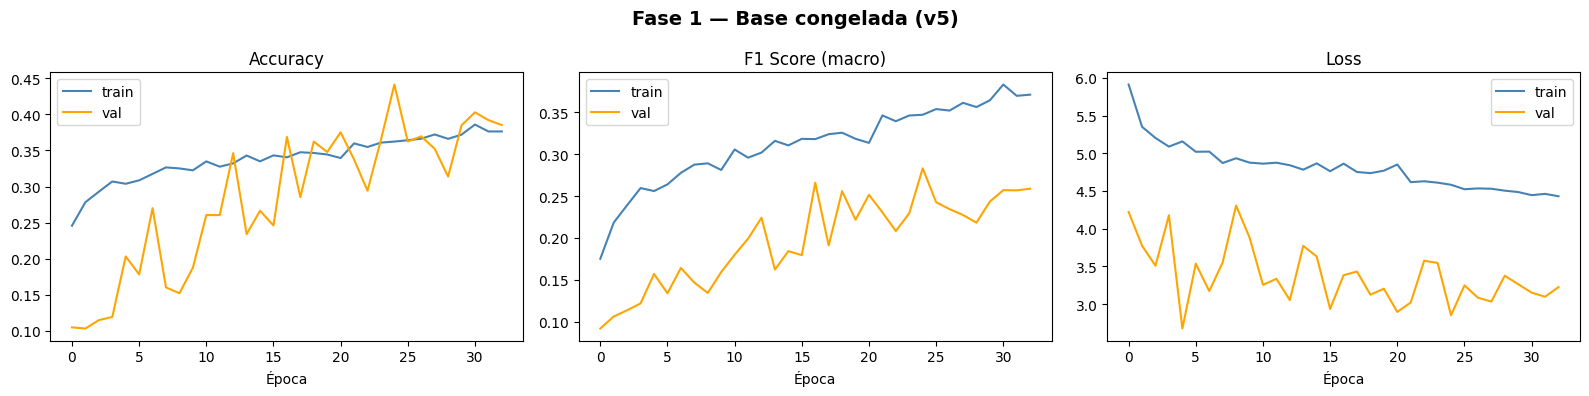

In [49]:
def plot_history(history, title, phase):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    fig.suptitle(title, fontsize=14, fontweight='bold')

    # Accuracy
    axes[0].plot(history.history['accuracy'],     label='train', color='steelblue')
    axes[0].plot(history.history['val_accuracy'], label='val',   color='orange')
    axes[0].set_title('Accuracy'); axes[0].legend(); axes[0].set_xlabel('Época')

    # F1 Macro
    axes[1].plot(history.history['macro_f1'],     label='train', color='steelblue')
    axes[1].plot(history.history['val_macro_f1'], label='val',   color='orange')
    axes[1].set_title('F1 Score (macro)'); axes[1].legend(); axes[1].set_xlabel('Época')

    # Loss
    axes[2].plot(history.history['loss'],     label='train', color='steelblue')
    axes[2].plot(history.history['val_loss'], label='val',   color='orange')
    axes[2].set_title('Loss'); axes[2].legend(); axes[2].set_xlabel('Época')

    plt.tight_layout()
    plt.savefig(os.path.join(MODELS_DIR, f'history_{phase}.png'), dpi=100, bbox_inches='tight')
    plt.show()

plot_history(history_phase1, 'Fase 1 — Base congelada (v5)', 'phase1')

## 13. FASE 2a — Fine-tuning: descongelar últimas 25 capas
### MEJORA 4: Fine-tuning gradual (en v4 se descongelaban ~50 capas de golpe)
- Descongelar solo las **últimas 25 capas** de DenseNet201
- LR bajo para no destruir lo aprendido en Fase 1
- **MEJORA 5**: LR warmup durante las primeras 5 épocas

In [95]:
# ─── Cargar mejor modelo de Fase 1 ──────────────────────────
model.load_weights(MODEL_PHASE1)
print(f"✅ Pesos de Fase 1 cargados desde: {MODEL_PHASE1}")

# ─── Descongelar últimas 25 capas ────────────────────────────
base_model.trainable = True
for layer in base_model.layers[:-UNFREEZE_PHASE2A]:
    layer.trainable = False

trainable_p2a = sum(tf.size(w).numpy() for w in model.trainable_variables)
frozen_count   = sum(1 for l in base_model.layers if not l.trainable)
unfrozen_count = sum(1 for l in base_model.layers if l.trainable)
print(f"Capas DenseNet congeladas:    {frozen_count}")
print(f"Capas DenseNet descongeladas: {unfrozen_count}")
print(f"Parámetros entrenables:       {trainable_p2a:,}")

# ─── Compilar para Fase 2a ───────────────────────────────────
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_PHASE2A),
    loss=focal_loss,
    metrics=[
        'accuracy',
        tf.keras.metrics.F1Score(average='macro', name='macro_f1')
    ]
)

# ─── Callbacks Fase 2a ───────────────────────────────────────
callbacks_phase2a = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=MODEL_PHASE2A,
        monitor='val_macro_f1',
        save_best_only=True,
        mode='max',
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_macro_f1',
        patience=8,
        restore_best_weights=True,
        mode='max',
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_macro_f1',
        factor=0.5,
        patience=4,
        min_lr=1e-8,
        mode='max',
        verbose=1
    ),
    LRWarmupCallback(base_lr=LR_PHASE2A, warmup_epochs=5),
]

print(f"\n✅ Listo para Fase 2a ({UNFREEZE_PHASE2A} capas descongeladas)")
print(f"   LR inicial (warmup): {LR_PHASE2A/5:.2e} → {LR_PHASE2A:.2e} en 5 épocas")

✅ Pesos de Fase 1 cargados desde: /kaggle/working/modelos_v5/densenet201_v5_phase1_best.keras
Capas DenseNet congeladas:    682
Capas DenseNet descongeladas: 25
Parámetros entrenables:       1,863,047

✅ Listo para Fase 2a (25 capas descongeladas)
   LR inicial (warmup): 4.00e-06 → 2.00e-05 en 5 épocas


### Ejecutar entrenamiento Fase 2a

In [96]:
history_phase2a = model.fit(
    train_ds,
    steps_per_epoch=steps_per_epoch_train,
    epochs=EPOCHS_PHASE2A,
    validation_data=val_ds,
    class_weight=class_weights,
    callbacks=callbacks_phase2a,
    verbose=1
)

print("\n✅ Fase 2a completada")
best_f1_p2a = max(history_phase2a.history['val_macro_f1'])
best_acc_p2a = max(history_phase2a.history['val_accuracy'])
print(f"   Mejor val_macro_f1:  {best_f1_p2a:.4f}  ({best_f1_p2a*100:.2f}%)")
print(f"   Mejor val_accuracy:  {best_acc_p2a:.4f}  ({best_acc_p2a*100:.2f}%)")

  [Warmup] Época 1/5 → LR = 4.00e-06
Epoch 1/25
437/437 ━━━━━━━━━━━━━━━━━━━━ 0s 302ms/step - accuracy: 0.3364 - loss: 7.2222 - macro_f1: 0.3156
Epoch 1: val_macro_f1 improved from None to 0.34035, saving model to /kaggle/working/modelos_v5/densenet201_v5_phase2a_best.keras

Epoch 1: finished saving model to /kaggle/working/modelos_v5/densenet201_v5_phase2a_best.keras
437/437 ━━━━━━━━━━━━━━━━━━━━ 244s 433ms/step - accuracy: 0.3417 - loss: 6.8538 - macro_f1: 0.3244 - val_accuracy: 0.5225 - val_loss: 3.4607 - val_macro_f1: 0.3403 - learning_rate: 4.0000e-06
  [Warmup] Época 2/5 → LR = 8.00e-06
Epoch 2/25
437/437 ━━━━━━━━━━━━━━━━━━━━ 0s 299ms/step - accuracy: 0.3573 - loss: 6.0121 - macro_f1: 0.3447
Epoch 2: val_macro_f1 improved from 0.34035 to 0.37116, saving model to /kaggle/working/modelos_v5/densenet201_v5_phase2a_best.keras

Epoch 2: finished saving model to /kaggle/working/modelos_v5/densenet201_v5_phase2a_best.keras
437/437 ━━━━━━━━━━━━━━━━━━━━ 178s 338ms/step - accuracy: 0.3604 - 

### Visualizar entrenamiento Fase 2a

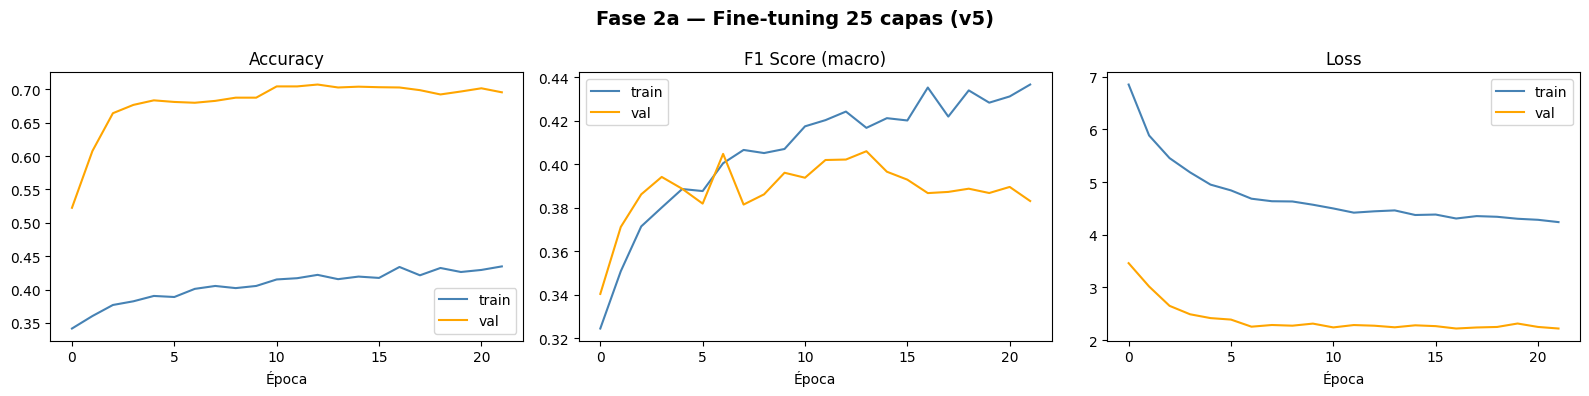

In [97]:
plot_history(history_phase2a, 'Fase 2a — Fine-tuning 25 capas (v5)', 'phase2a')

## 14. FASE 2b — Fine-tuning: descongelar últimas 100 capas
- Descongelar ahora las **últimas 100 capas** de DenseNet201
- LR más bajo: `5e-6` para ajuste muy delicado
- **MEJORA 5**: LR warmup durante las primeras 5 épocas

In [98]:
# ─── Cargar mejor modelo de Fase 2a ─────────────────────────
model.load_weights(MODEL_PHASE2A)
print(f"✅ Pesos de Fase 2a cargados desde: {MODEL_PHASE2A}")

# ─── Descongelar últimas 100 capas ───────────────────────────
base_model.trainable = True
for layer in base_model.layers[:-UNFREEZE_PHASE2B]:
    layer.trainable = False

trainable_p2b = sum(tf.size(w).numpy() for w in model.trainable_variables)
frozen_count  = sum(1 for l in base_model.layers if not l.trainable)
unfrozen_count= sum(1 for l in base_model.layers if l.trainable)
print(f"Capas DenseNet congeladas:    {frozen_count}")
print(f"Capas DenseNet descongeladas: {unfrozen_count}")
print(f"Parámetros entrenables:       {trainable_p2b:,}")

# ─── Compilar para Fase 2b ───────────────────────────────────
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_PHASE2B),
    loss=focal_loss,
    metrics=[
        'accuracy',
        tf.keras.metrics.F1Score(average='macro', name='macro_f1')
    ]
)

# ─── Callbacks Fase 2b ───────────────────────────────────────
callbacks_phase2b = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=MODEL_PHASE2B,
        monitor='val_macro_f1',
        save_best_only=True,
        mode='max',
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_macro_f1',
        patience=8,
        restore_best_weights=True,
        mode='max',
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_macro_f1',
        factor=0.5,
        patience=4,
        min_lr=1e-8,
        mode='max',
        verbose=1
    ),
    # ↑ MEJORA 5: LR Warmup
    LRWarmupCallback(base_lr=LR_PHASE2B, warmup_epochs=5),
]

print(f"\n✅ Listo para Fase 2b ({UNFREEZE_PHASE2B} capas descongeladas)")
print(f"   LR inicial (warmup): {LR_PHASE2B/5:.2e} → {LR_PHASE2B:.2e} en 5 épocas")

✅ Pesos de Fase 2a cargados desde: /kaggle/working/modelos_v5/densenet201_v5_phase2a_best.keras
Capas DenseNet congeladas:    682
Capas DenseNet descongeladas: 25
Parámetros entrenables:       1,863,047

✅ Listo para Fase 2b (100 capas descongeladas)
   LR inicial (warmup): 1.00e-06 → 5.00e-06 en 5 épocas


### Ejecutar entrenamiento Fase 2b

In [99]:
history_phase2b = model.fit(
    train_ds,
    steps_per_epoch=steps_per_epoch_train,
    epochs=EPOCHS_PHASE2B,
    validation_data=val_ds,
    class_weight=class_weights,
    callbacks=callbacks_phase2b,
    verbose=1
)

print("\n✅ Fase 2b completada")
best_f1_p2b = max(history_phase2b.history['val_macro_f1'])
best_acc_p2b = max(history_phase2b.history['val_accuracy'])
print(f"   Mejor val_macro_f1:  {best_f1_p2b:.4f}  ({best_f1_p2b*100:.2f}%)")
print(f"   Mejor val_accuracy:  {best_acc_p2b:.4f}  ({best_acc_p2b*100:.2f}%)")

  [Warmup] Época 1/5 → LR = 1.00e-06
Epoch 1/25
437/437 ━━━━━━━━━━━━━━━━━━━━ 0s 303ms/step - accuracy: 0.4304 - loss: 4.3604 - macro_f1: 0.4315
Epoch 1: val_macro_f1 improved from None to 0.39677, saving model to /kaggle/working/modelos_v5/densenet201_v5_phase2b_best.keras

Epoch 1: finished saving model to /kaggle/working/modelos_v5/densenet201_v5_phase2b_best.keras
437/437 ━━━━━━━━━━━━━━━━━━━━ 239s 434ms/step - accuracy: 0.4309 - loss: 4.3040 - macro_f1: 0.4322 - val_accuracy: 0.7047 - val_loss: 2.2324 - val_macro_f1: 0.3968 - learning_rate: 1.0000e-06
  [Warmup] Época 2/5 → LR = 2.00e-06
Epoch 2/25
437/437 ━━━━━━━━━━━━━━━━━━━━ 0s 302ms/step - accuracy: 0.4173 - loss: 4.4465 - macro_f1: 0.4188
Epoch 2: val_macro_f1 improved from 0.39677 to 0.40121, saving model to /kaggle/working/modelos_v5/densenet201_v5_phase2b_best.keras

Epoch 2: finished saving model to /kaggle/working/modelos_v5/densenet201_v5_phase2b_best.keras
437/437 ━━━━━━━━━━━━━━━━━━━━ 181s 355ms/step - accuracy: 0.4129 - 

### Visualizar entrenamiento Fase 2b

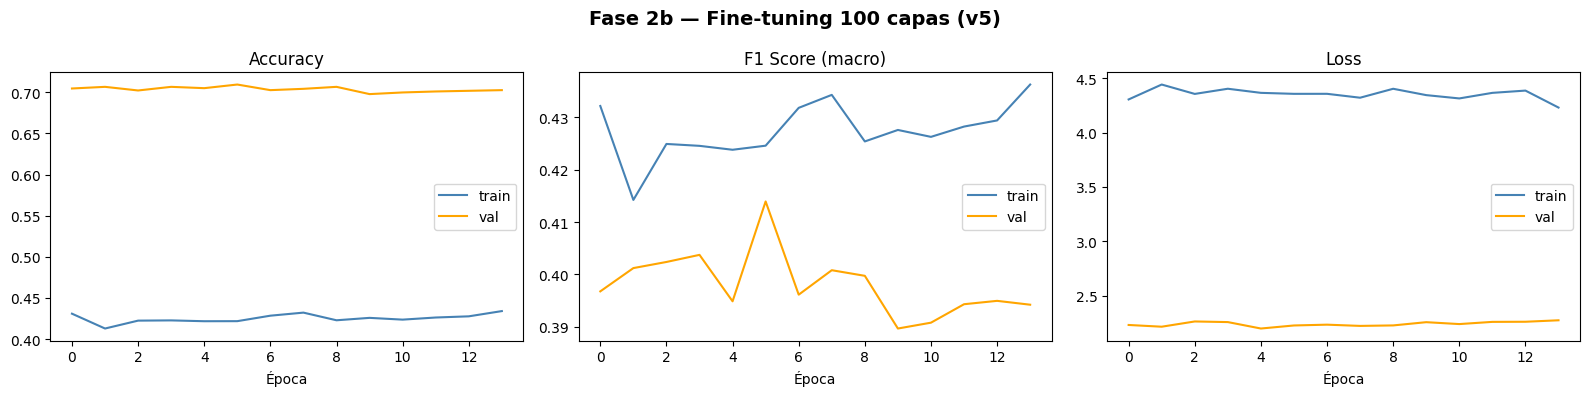

In [100]:
plot_history(history_phase2b, 'Fase 2b — Fine-tuning 100 capas (v5)', 'phase2b')

## 15. Evaluación final en test set
El test set nunca fue usado durante el entrenamiento ni para seleccionar el mejor modelo.

In [101]:
# ─── Cargar mejor modelo de toda la secuencia ───────────────
model.load_weights(MODEL_PHASE2B)
print(f"✅ Pesos finales cargados (mejor Fase 2b)")

# ─── Evaluar en test ─────────────────────────────────────────
print("\nEvaluando en test set...")
test_loss, test_acc, test_f1 = model.evaluate(test_ds, verbose=0)
print(f"\n{'='*50}")
print(f"  Test Accuracy:   {test_acc*100:.2f}%")
print(f"  Test F1 (macro): {test_f1*100:.2f}%")
print(f"  Test Loss:       {test_loss:.4f}")
print(f"{'='*50}")

# Comparativa con versiones anteriores
print("\nComparativa de versiones:")
print(f"  v1: accuracy=54.33%,  F1=~5%   (sin balanceo — predecía siempre nv)")
print(f"  v2: val_acc=34.35%,   F1=~?    (Focal Loss en Fase 1 → convergencia lenta)")
print(f"  v3: accuracy=66.77%,  F1=11.44% (CrossEntropy Fase 1 ✓, sin .repeat())")
print(f"  v4: accuracy=43.81%,  F1=15.29% (class_weights corregidos, .repeat() faltaba)")
print(f"  v5: accuracy={test_acc*100:.2f}%,  F1={test_f1*100:.2f}% (TODAS LAS MEJORAS ✓)")

✅ Pesos finales cargados (mejor Fase 2b)

Evaluando en test set...

  Test Accuracy:   68.79%
  Test F1 (macro): 43.62%
  Test Loss:       2.2503

Comparativa de versiones:
  v1: accuracy=54.33%,  F1=~5%   (sin balanceo — predecía siempre nv)
  v2: val_acc=34.35%,   F1=~?    (Focal Loss en Fase 1 → convergencia lenta)
  v3: accuracy=66.77%,  F1=11.44% (CrossEntropy Fase 1 ✓, sin .repeat())
  v4: accuracy=43.81%,  F1=15.29% (class_weights corregidos, .repeat() faltaba)
  v5: accuracy=68.79%,  F1=43.62% (TODAS LAS MEJORAS ✓)


## 16. Reporte detallado y matriz de confusión

Reporte de clasificación (test set):
              precision    recall  f1-score   support

       akiec     1.0000    0.0238    0.0465        42
         bcc     0.3538    0.6866    0.4670        67
         bkl     0.3189    0.6761    0.4334       142
          df     0.8000    0.2857    0.4211        14
         mel     0.0000    0.0000    0.0000       144
          nv     0.8738    0.8392    0.8561       858
        vasc     0.7391    0.9444    0.8293        18

    accuracy                         0.6879      1285
   macro avg     0.5837    0.4937    0.4362      1285
weighted avg     0.6889    0.6879    0.6616      1285



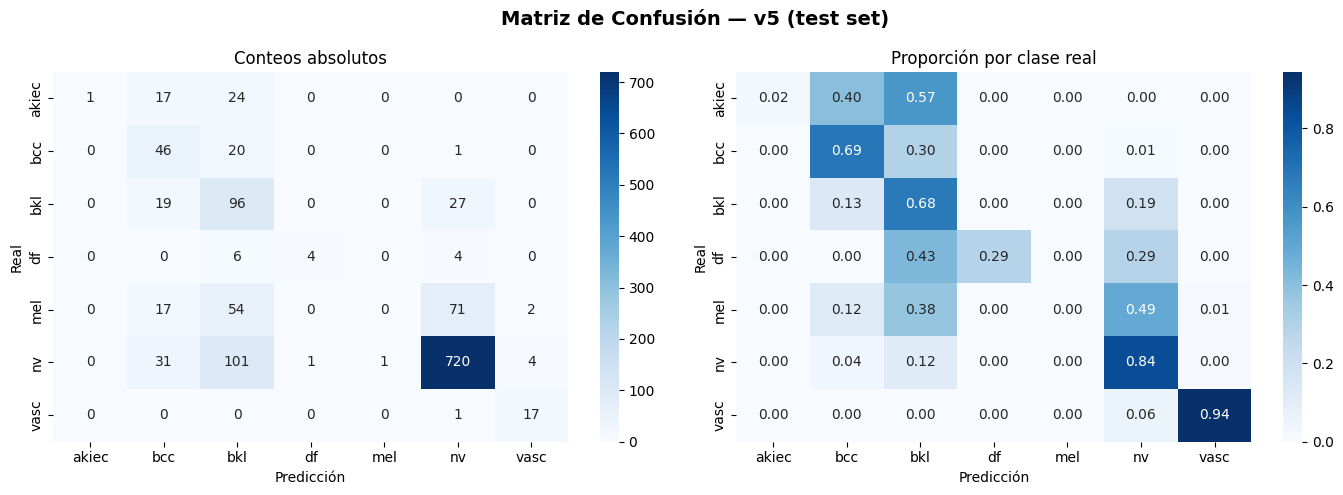

In [102]:
# ─── Predicciones ────────────────────────────────────────────
y_pred_probs = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = y_test_raw

# ─── Reporte de clasificación ────────────────────────────────
print("Reporte de clasificación (test set):")
print("="*70)
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

# ─── Matriz de confusión ─────────────────────────────────────
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Matriz de Confusión — v5 (test set)', fontsize=14, fontweight='bold')

# Sin normalizar
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title('Conteos absolutos')
axes[0].set_xlabel('Predicción'); axes[0].set_ylabel('Real')

# Normalizada
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1])
axes[1].set_title('Proporción por clase real')
axes[1].set_xlabel('Predicción'); axes[1].set_ylabel('Real')

plt.tight_layout()
plt.savefig(os.path.join(MODELS_DIR, 'confusion_matrix_v5.png'), dpi=100, bbox_inches='tight')
plt.show()

## 17. Resumen de mejoras aplicadas en v5

In [104]:
print("="*60)
print("RESUMEN DE MEJORAS v5")
print("="*60)
print()
print("MEJORA 1 — Fix .repeat() [CRÍTICO]")
print("  v4: solo 300/437 steps por época (31% datos perdidos)")
print("  v5: todos los 437 steps corren completos cada época")
print()
print("MEJORA 2 — Augmentation diferenciada por clase")
print("  Clases raras (df, vasc, akiec):")
print("    flip H+V, rotation±30%, zoom±20%,")
print("    contrast±30%, brightness±20%, translation±10%")
print("  Clases normales (mel, bkl, bcc, nv):")
print("    flip H, rotation±10%, zoom±10%, brightness±10%")
print()
print("MEJORA 3 — Fase 1: 40 épocas (↑ de 30)")
print("  Con .repeat() corregido, 40 épocas = 40 épocas reales")
print("  v4 real: ~21 épocas efectivas por el bug")
print()
print("MEJORA 4 — Fine-tuning gradual")
print("  Fase 2a: 25 capas descongeladas, LR=2e-5")
print("  Fase 2b: 100 capas descongeladas, LR=5e-6")
print("  v4: descongelaba ~50 capas de golpe sin progresión")
print()
print("MEJORA 5 — LR Warmup en Fases 2a y 2b")
print("  Épocas 1-5: LR sube linealmente de LR/5 hasta LR")
print("  Protege pesos de la fase anterior durante transición")
print()
print("="*60)
print(f"RESULTADO FINAL:")
print(f"  Test Accuracy:   {test_acc*100:.2f}%  (v4: 43.81%)")
print(f"  Test F1 (macro): {test_f1*100:.2f}%  (v4: 15.29%)")
print("="*60)

RESUMEN DE MEJORAS v5

MEJORA 1 — Fix .repeat() [CRÍTICO]
  v4: solo 300/437 steps por época (31% datos perdidos)
  v5: todos los 437 steps corren completos cada época

MEJORA 2 — Augmentation diferenciada por clase
  Clases raras (df, vasc, akiec):
    flip H+V, rotation±30%, zoom±20%,
    contrast±30%, brightness±20%, translation±10%
  Clases normales (mel, bkl, bcc, nv):
    flip H, rotation±10%, zoom±10%, brightness±10%

MEJORA 3 — Fase 1: 40 épocas (↑ de 30)
  Con .repeat() corregido, 40 épocas = 40 épocas reales
  v4 real: ~21 épocas efectivas por el bug

MEJORA 4 — Fine-tuning gradual
  Fase 2a: 25 capas descongeladas, LR=2e-5
  Fase 2b: 100 capas descongeladas, LR=5e-6
  v4: descongelaba ~50 capas de golpe sin progresión

MEJORA 5 — LR Warmup en Fases 2a y 2b
  Épocas 1-5: LR sube linealmente de LR/5 hasta LR
  Protege pesos de la fase anterior durante transición

RESULTADO FINAL:
  Test Accuracy:   68.79%  (v4: 43.81%)
  Test F1 (macro): 43.62%  (v4: 15.29%)
